# Midway project review

Regenerates every figure in the README from `data/` (written by `compute_funnel.py`, which reads the existing T10 tables, ranker v0 top-1 files and `benchmarks/detectability_dev.csv`; no pipeline runs).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import FancyBboxPatch
HERE = Path('.').resolve()
D, F = HERE / 'data', HERE / 'figures'
F.mkdir(exist_ok=True)
BINS = ['<1d', '1-3d', '3-10d', '10-30d', '>30d']
funnel = pd.read_csv(D / 'funnel.csv'); weights = pd.read_csv(D / 'weighting.csv')
chance = pd.read_csv(D / 'chance_final.csv'); cov = pd.read_csv(D / 'coverage_class.csv')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

## Figure 1: where stars are lost, per period bin

Nested stages, each a fraction of *all* stars in the bin: detectable (T26, D_band·√N_cyc ≥ 5) → and a correct/diffrot candidate survives into the fit → and ranker v0 puts it first → and ranker v0 answers (score ≥ its threshold). Black ticks: hand arbitration's success (all stars). Grey diamonds: candidate-present rate for *all* stars when truth is shuffled within the bin (chance).

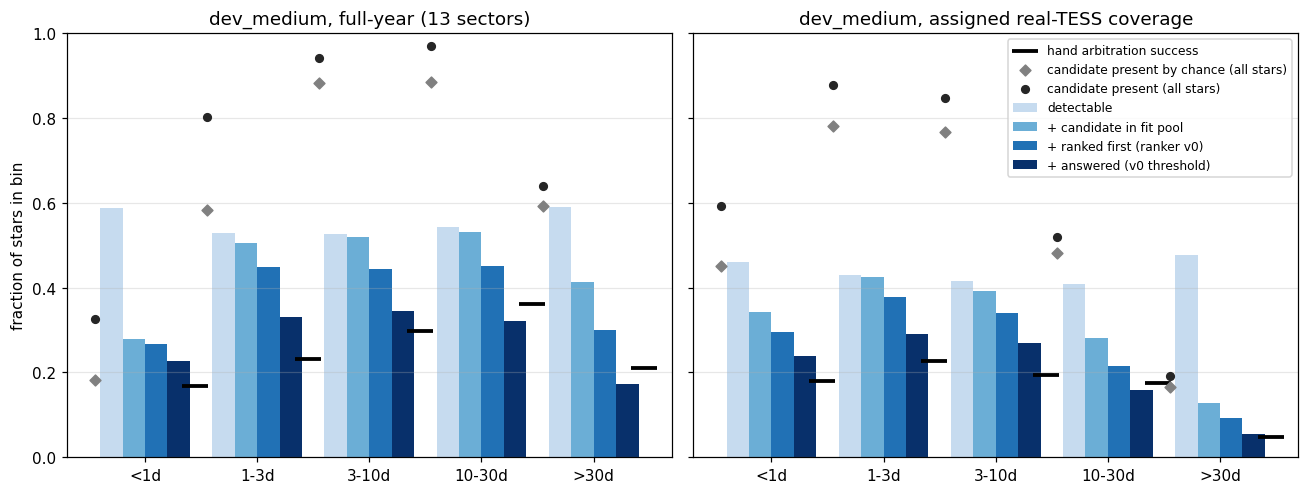

In [2]:
cols = [('detectable', 'detectable', '#c6dbef'), ('det_cand', '+ candidate in fit pool', '#6baed6'),
        ('det_cand_top1', '+ ranked first (ranker v0)', '#2171b5'), ('det_ranker_answer_ok', '+ answered (v0 threshold)', '#08306b')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, mode, title in zip(axes, ['fullyear', 'assigned'], ['full-year (13 sectors)', 'assigned real-TESS coverage']):
    g = funnel[funnel['mode'] == mode].set_index('bin').loc[BINS]
    x = np.arange(len(BINS)); w = 0.2
    for i, (c, lab, col) in enumerate(cols):
        ax.bar(x + (i - 1.5) * w, g[c], w, color=col, label=lab)
    ax.scatter(x + 0.45, g['hand_success'], marker='_', s=300, color='k', lw=2.5, label='hand arbitration success', zorder=5)
    ax.scatter(x - 0.45, g['cand_chance'], marker='D', s=25, color='0.5', label='candidate present by chance (all stars)', zorder=5)
    ax.scatter(x - 0.45, g['cand_any'], marker='o', s=25, color='0.15', label='candidate present (all stars)', zorder=5)
    ax.set_xticks(x, BINS); ax.set_title(f'dev_medium, {title}'); ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=.3)
axes[0].set_ylabel('fraction of stars in bin'); axes[1].legend(fontsize=8, loc='upper right')
fig.tight_layout(); fig.savefig(F / 'fig1_loss_funnel.png', bbox_inches='tight')

Overall (all 1,000 stars): full-year detectable 0.56 → candidate 0.445 → first 0.37 → answered 0.264 (ranker v0 success on all stars 0.267); assigned 0.444 → 0.287 → 0.240 → 0.181 (0.188).

In [3]:
for mode in ['fullyear', 'assigned']:
    g = funnel[funnel['mode'] == mode]
    print(mode, {c: round((g[c] * g.n).sum() / g.n.sum(), 3) for c in ['detectable', 'det_cand', 'det_cand_top1', 'det_ranker_answer_ok', 'hand_success']})

fullyear {'detectable': 0.56, 'det_cand': 0.445, 'det_cand_top1': 0.37, 'det_ranker_answer_ok': 0.264, 'hand_success': 0.248}
assigned {'detectable': 0.444, 'det_cand': 0.287, 'det_cand_top1': 0.24, 'det_ranker_answer_ok': 0.181, 'hand_success': 0.148}


## Figure 2: pipeline diagram with the weak points marked

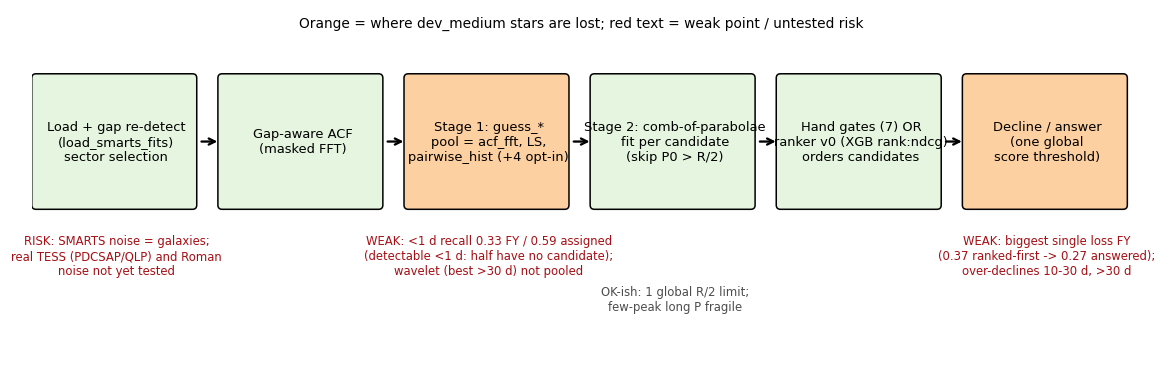

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.2)); ax.set_xlim(0, 13.1); ax.set_ylim(0, 4.2); ax.axis('off')
boxes = [(0.05, 'Load + gap re-detect\n(load_smarts_fits)\nsector selection', '#e5f5e0'),
         (2.25, 'Gap-aware ACF\n(masked FFT)', '#e5f5e0'),
         (4.45, 'Stage 1: guess_*\npool = acf_fft, LS,\npairwise_hist (+4 opt-in)', '#fdd0a2'),
         (6.65, 'Stage 2: comb-of-parabolae\nfit per candidate\n(skip P0 > R/2)', '#e5f5e0'),
         (8.85, 'Hand gates (7) OR\nranker v0 (XGB rank:ndcg)\norders candidates', '#e5f5e0'),
         (11.05, 'Decline / answer\n(one global\nscore threshold)', '#fdd0a2')]
for x, t, c in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.9), 1.85, 1.5, boxstyle='round,pad=0.05', fc=c, ec='k'))
    ax.text(x + 0.95, 2.65, t, ha='center', va='center', fontsize=8.5)
for x, _, _ in boxes[:-1]:
    ax.annotate('', xy=(x + 2.18, 2.65), xytext=(x + 1.92, 2.65), arrowprops=dict(arrowstyle='->', lw=1.5))
weak = [(4.45, 'WEAK: <1 d recall 0.33 FY / 0.59 assigned\n(detectable <1 d: half have no candidate);\nwavelet (best >30 d) not pooled'),
        (11.05, 'WEAK: biggest single loss FY\n(0.37 ranked-first -> 0.27 answered);\nover-declines 10-30 d, >30 d'),
        (0.05, 'RISK: SMARTS noise = galaxies;\nreal TESS (PDCSAP/QLP) and Roman\nnoise not yet tested'),
        (6.65, 'OK-ish: 1 global R/2 limit;\nfew-peak long P fragile')]
for x, t in weak:
    ax.text(x + 0.95, 1.55 if t.startswith(('WEAK', 'RISK')) else 0.95, t, ha='center', va='top', fontsize=7.6, color='#a50f15' if t.startswith(('WEAK', 'RISK')) else '0.3')
ax.text(6.5, 4.0, 'Orange = where dev_medium stars are lost; red text = weak point / untested risk', ha='center', fontsize=9)
fig.savefig(F / 'fig2_pipeline_weak_points.png', bbox_inches='tight')

## Figure 3: headline sensitivity to coverage and population weighting

real-TESS coverage mix, P<=30 d: hand 0.116 ranker 0.198


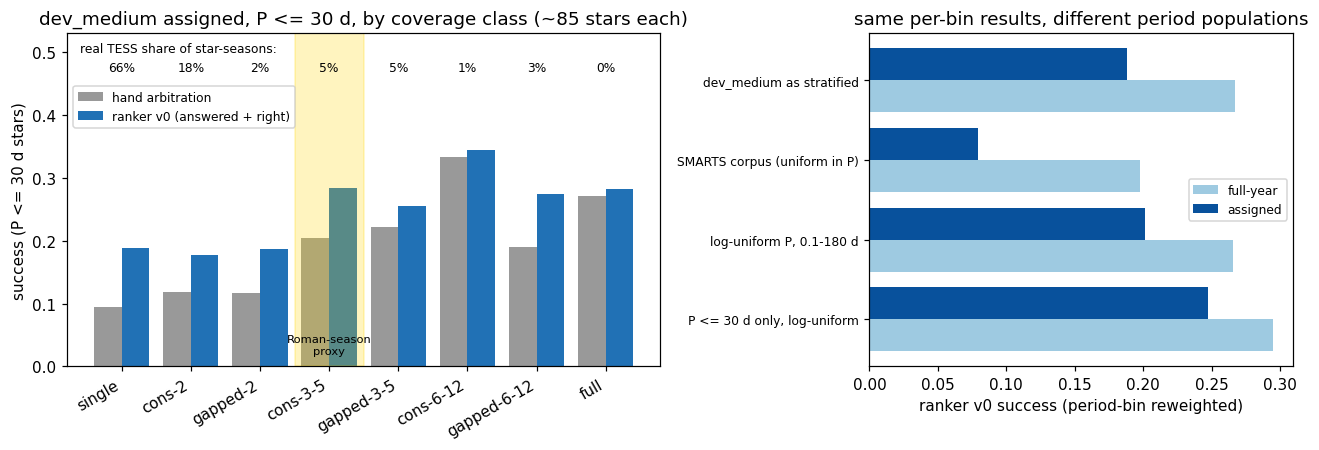

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
c = cov[cov.P_le_30].set_index('coverage_class')
order = ['single', 'consecutive-2', 'gapped-2', 'consecutive-3-5', 'gapped-3-5', 'consecutive-6-12', 'gapped-6-12', 'full']
c = c.loc[order]; x = np.arange(len(order))
a1.bar(x - 0.2, c.success, 0.4, label='hand arbitration', color='0.6')
a1.bar(x + 0.2, c.ranker_answer_ok, 0.4, label='ranker v0 (answered + right)', color='#2171b5')
share = c.coverage_weight * c.n; share = share / share.sum()
for xi, s in zip(x, share):
    a1.text(xi, 0.47, f'{s:.0%}', ha='center', fontsize=8)
a1.text(-0.6, 0.50, 'real TESS share of star-seasons:', fontsize=8)
a1.set_xticks(x, [o.replace('consecutive', 'cons') for o in order], rotation=30, ha='right')
a1.set_ylim(0, 0.53); a1.set_ylabel('success (P <= 30 d stars)'); a1.legend(fontsize=8, loc='upper left', bbox_to_anchor=(0, 0.86))
a1.set_title('dev_medium assigned, P <= 30 d, by coverage class (~85 stars each)')
a1.axvspan(2.5, 3.5, color='gold', alpha=0.25); a1.text(3, 0.02, 'Roman-season\nproxy', ha='center', fontsize=7.5)
wts = weights[weights['mode'] == 'assigned'].set_index('weighting')
wf = weights[weights['mode'] == 'fullyear'].set_index('weighting')
y = np.arange(len(wts))
a2.barh(y + 0.2, wf.ranker_v0_at_threshold, 0.4, color='#9ecae1', label='full-year')
a2.barh(y - 0.2, wts.ranker_v0_at_threshold, 0.4, color='#08519c', label='assigned')
a2.set_yticks(y, wts.index, fontsize=8); a2.invert_yaxis(); a2.set_xlabel('ranker v0 success (period-bin reweighted)')
a2.set_title('same per-bin results, different period populations'); a2.legend(fontsize=8)
fig.tight_layout(); fig.savefig(F / 'fig3_coverage_weighting.png', bbox_inches='tight')
w_real = (c.success * share).sum(); r_real = (c.ranker_answer_ok * share).sum()
print('real-TESS coverage mix, P<=30 d: hand', round(w_real, 3), 'ranker', round(r_real, 3))

## Figure 4: are successes chance coincidences with wide success windows?

Success rate among answered stars vs the same answers shuffled among stars of the same period bin (200 permutations).

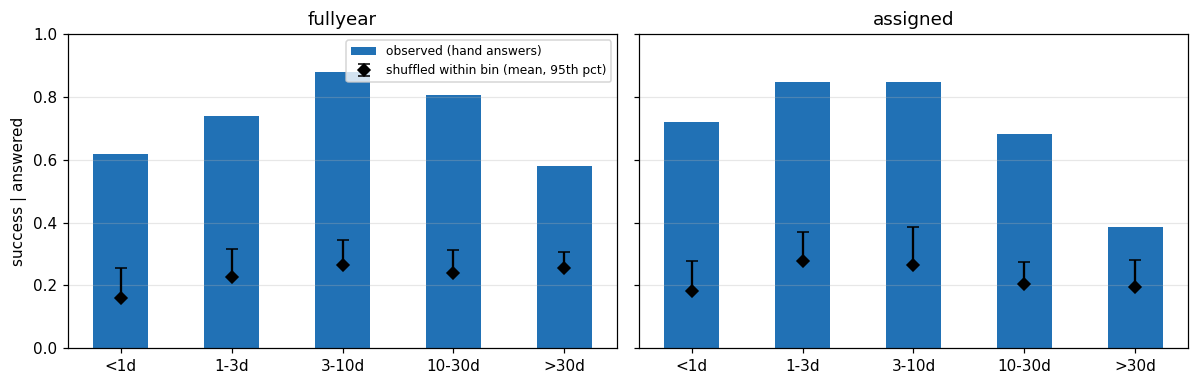

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, mode in zip(axes, ['fullyear', 'assigned']):
    g = chance[chance['mode'] == mode].set_index('bin').loc[BINS]; x = np.arange(len(BINS))
    ax.bar(x, g.obs_success_given_answer, 0.5, color='#2171b5', label='observed (hand answers)')
    ax.errorbar(x, g.null_mean, yerr=[np.zeros(len(x)), g.null_p95 - g.null_mean], fmt='D', color='k', capsize=4,
                label='shuffled within bin (mean, 95th pct)')
    ax.set_xticks(x, BINS); ax.set_title(mode); ax.set_ylim(0, 1); ax.grid(axis='y', alpha=.3)
axes[0].set_ylabel('success | answered'); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(F / 'fig4_chance_null.png', bbox_inches='tight')

## Figure 5: answer precision depends on how many stars are non-rotators

Per-star rates quoted from the T11 and T27 report TL;DRs (dev_medium; wrong includes aliases where the report gives them); the non-rotator FP rate is from T27's galaxy-stack negatives, which are cleaner than real non-rotating stars.

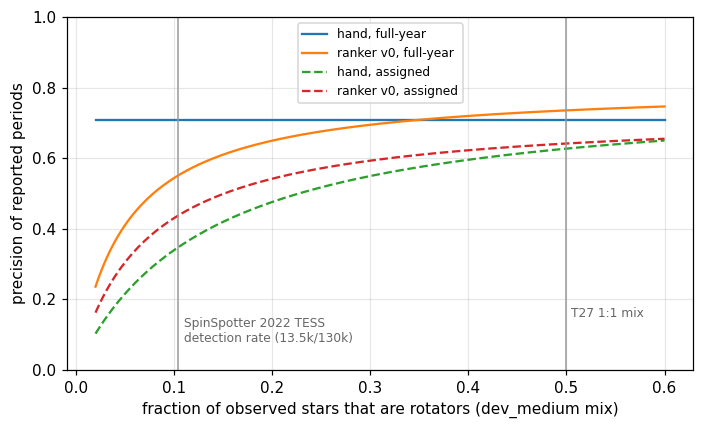

In [7]:
rates = {  # (success, wrong incl. alias, non-rotator FP) per star
    'hand, full-year': (0.248, 0.102, 0.000), 'ranker v0, full-year': (0.267, 0.080, 0.016),
    'hand, assigned': (0.148, 0.063, 0.025), 'ranker v0, assigned': (0.188, 0.087, 0.018)}
f = np.linspace(0.02, 0.6, 200)
fig, ax = plt.subplots(figsize=(6.5, 4))
for (k, (ok, wr, fp)), ls in zip(rates.items(), ['-', '-', '--', '--']):
    ax.plot(f, f * ok / (f * ok + f * wr + (1 - f) * fp), ls, label=k)
ax.axvline(0.5, color='0.6', lw=1); ax.text(0.505, 0.15, 'T27 1:1 mix', fontsize=8, color='0.4')
ax.axvline(0.104, color='0.6', lw=1); ax.text(0.11, 0.08, 'SpinSpotter 2022 TESS\ndetection rate (13.5k/130k)', fontsize=8, color='0.4')
ax.set_xlabel('fraction of observed stars that are rotators (dev_medium mix)'); ax.set_ylabel('precision of reported periods')
ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(F / 'fig5_precision_vs_prevalence.png', bbox_inches='tight')